In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

In [70]:
df=pd.read_csv("carprices (1).csv")

In [71]:
df.describe()

,Mileage,Sell Price($),Age(yrs)
count,13.000000,13.000000,13.000000
mean,60884.615385,26023.076923,5.307692
std,19185.665055,8003.661021,1.652504
min,22500.000000,12000.000000,2.000000
25%,52000.000000,20000.000000,5.000000
50%,59000.000000,26100.000000,5.000000
75%,72000.000000,32000.000000,6.000000
max,91000.000000,40000.000000,8.000000


In [72]:
df.head()

,Car Model,Mileage,Sell Price($),Age(yrs)
0,BMW X5,69000,18000,6
1,BMW X5,35000,34000,3
2,BMW X5,57000,26100,5
3,BMW X5,22500,40000,2
4,BMW X5,46000,31500,4


In [73]:
col_num=['Mileage','Age(yrs)']

In [74]:
from scipy.stats import skew

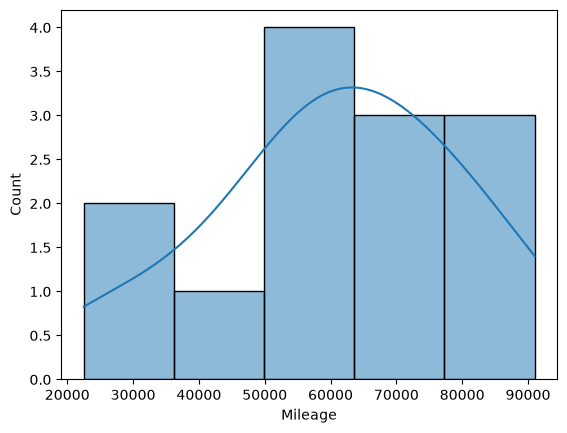

-0.3900594574431897


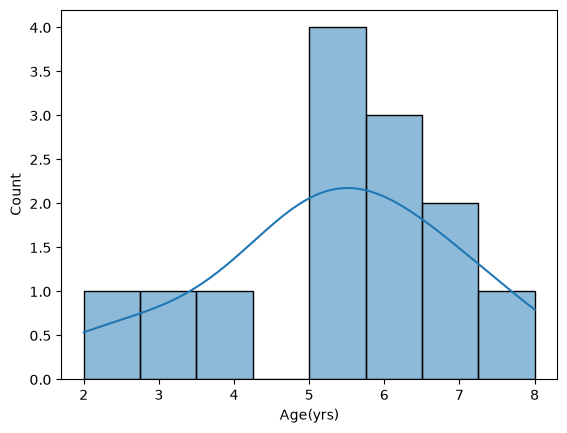

-0.39647242223631923


In [75]:
for col in col_num:
    plt.figure()
    sns.histplot(df[col],kde=True)
    plt.show()
    print(skew(df[col]))

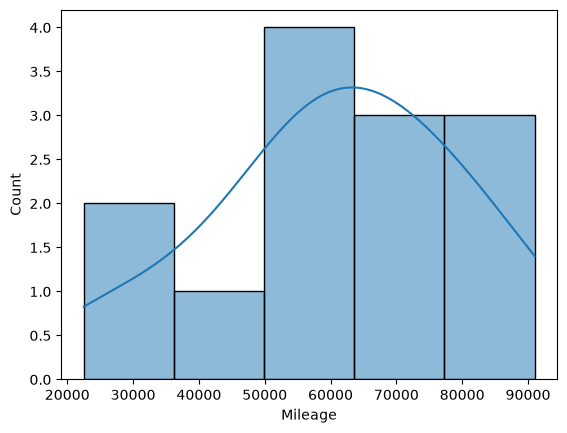

-0.3900594574431897


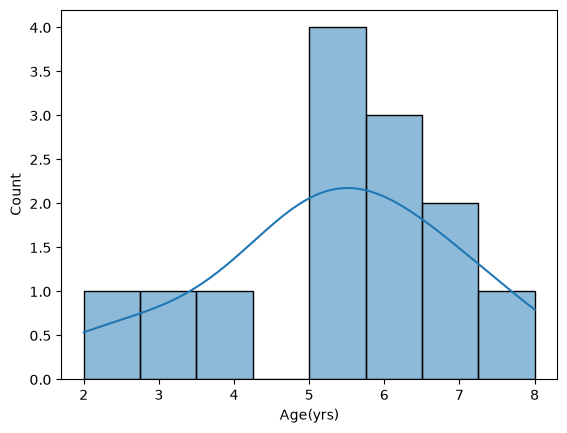

-0.39647242223631923


In [76]:
for col in col_num:
    plt.figure()
    sns.histplot(df[col],kde=True)
    plt.show()
    print(skew(df[col]))

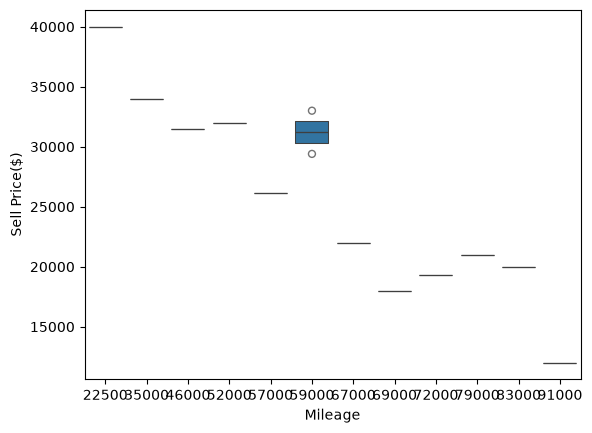

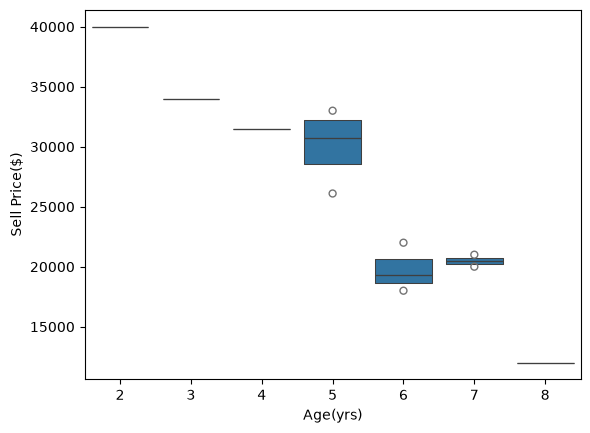

In [77]:
for col in col_num:
    plt.figure()
    sns.boxenplot(x=df[col],y=df["Sell Price($)"])


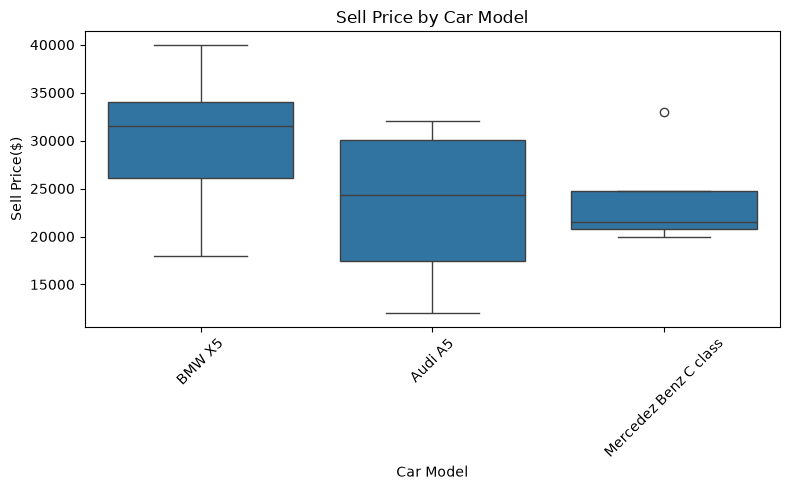

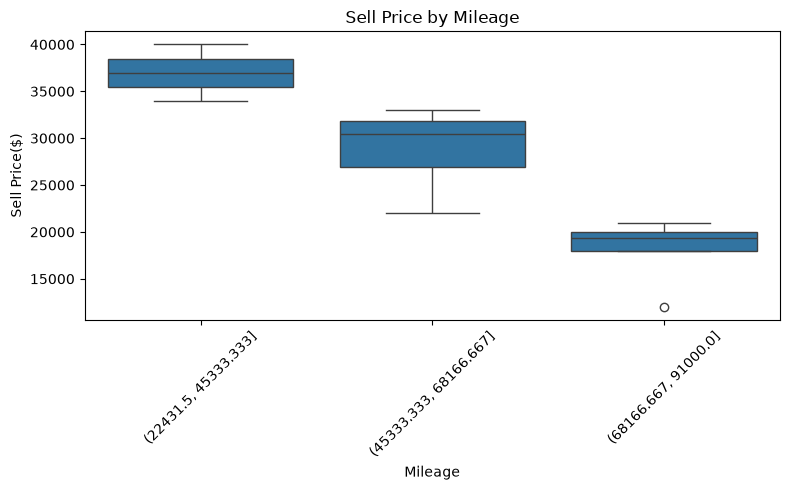

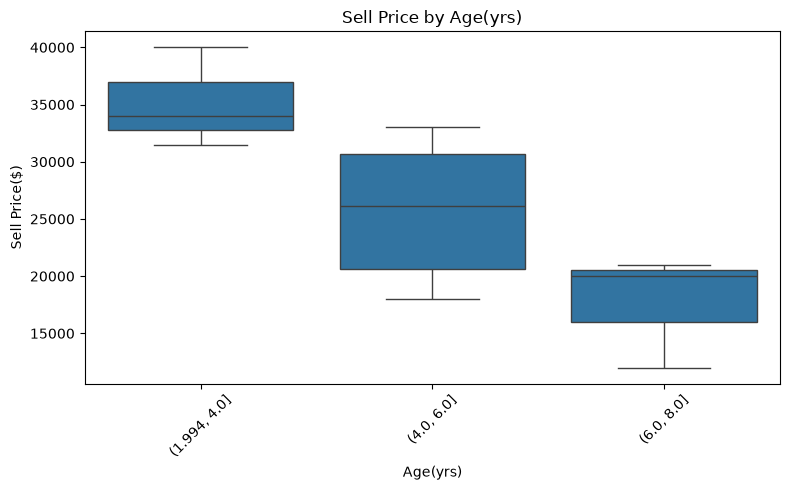

In [78]:
plot_columns = ['Car Model', 'Mileage', 'Age(yrs)']

for column in plot_columns:
    plot_df = df.copy()
    if column != 'Car Model':
        plot_df[column] = pd.cut(plot_df[column], bins=3)

    plt.figure(figsize=(8, 5))
    sns.boxplot(data=plot_df, x=column, y='Sell Price($)')
    plt.title(f'Sell Price by {column}')
    plt.xlabel(column)
    plt.ylabel('Sell Price($)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

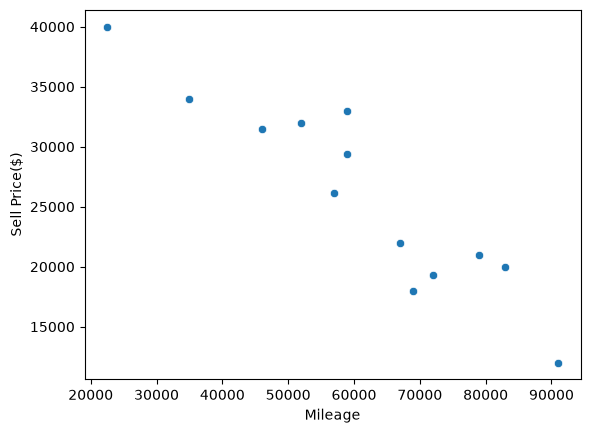

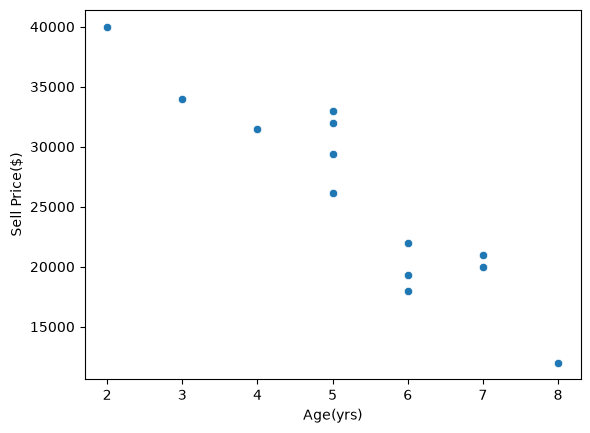

In [79]:
for col in col_num:
    plt.figure()
    sns.scatterplot(x=df[col],y=df["Sell Price($)"])


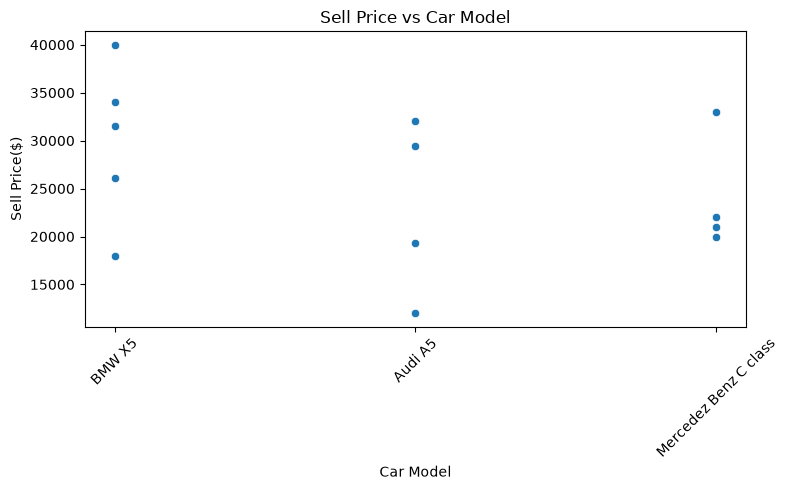

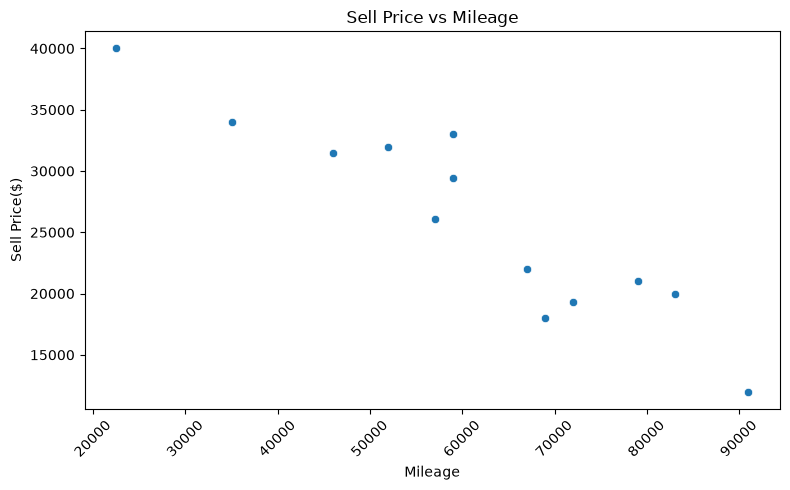

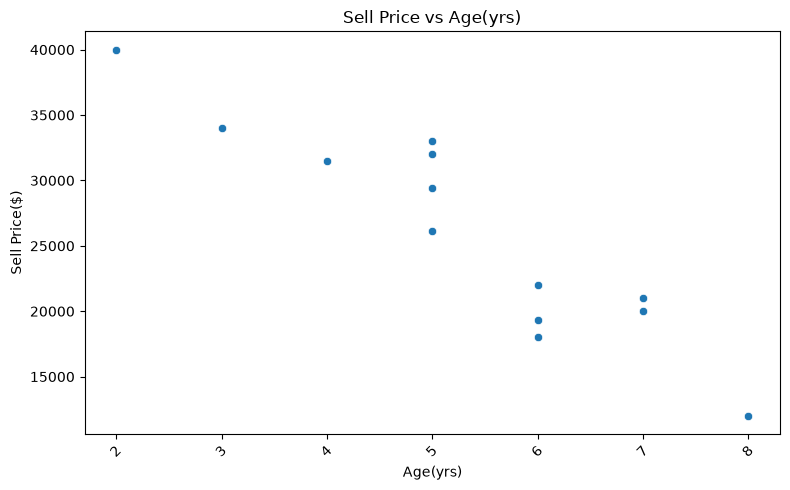

In [80]:
scatter_columns = ['Car Model', 'Mileage', 'Age(yrs)']

for column in scatter_columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=column, y='Sell Price($)')
    plt.title(f'Sell Price vs {column}')
    plt.xlabel(column)
    plt.ylabel('Sell Price($)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [81]:
numeric_df = df.select_dtypes(include="int")

In [82]:
numeric_df.head()

,Mileage,Sell Price($),Age(yrs)
0,69000,18000,6
1,35000,34000,3
2,57000,26100,5
3,22500,40000,2
4,46000,31500,4


<Axes: >

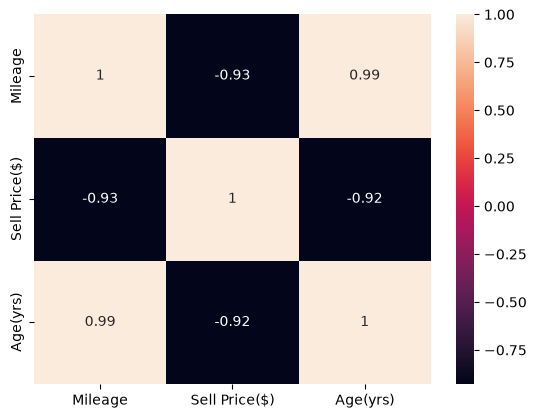

In [83]:
sns.heatmap(numeric_df.corr(),annot=True)

In [84]:
# one hot encoding

In [85]:
car_model_col=pd.get_dummies(df['Car Model'],dtype="int")

In [86]:
df_new=pd.concat([df,car_model_col],axis=1)
df_new.drop('Car Model',axis=1,inplace=True)

In [87]:
df_new.tail()

,Mileage,Sell Price($),Age(yrs),Audi A5,BMW X5,Mercedez Benz C class
8,91000,12000,8,1,0,0
9,67000,22000,6,0,0,1
10,83000,20000,7,0,0,1
11,79000,21000,7,0,0,1
12,59000,33000,5,0,0,1


In [88]:
X=df_new.drop('Sell Price($)',axis=1)
y=df_new['Sell Price($)']

In [89]:
from sklearn.model_selection import cross_val_score

In [90]:
model=RandomForestRegressor(n_estimators=100)

In [91]:
cv=cross_val_score(
    model,
    X,y,cv=5,
    scoring="r2"
)

In [92]:
cv

array([ 0.58703184, -0.13855584,  0.64170307, -0.255145  ,  0.69256328])

In [93]:
print(cv.mean())

0.3055194715003126


In [94]:
# Boosting :-
# 1]Ada Boosting(Adaptive Boosting) -> Decision stump
# 2]Gradient Boosting
# 3]XG Boosting(Extreme ge)